In [17]:
import pandas as pd
import random
from math import sqrt
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

In [61]:
COLS = 40
ROWS = 30

COLORS = [
    "#7A1B27",
    "#B65226",
    "#CA6B16",
    "#C5852F",
    "#CC9526",
    "#989629",
    "#3D6536",
    "#015852",
    "#366E7F",
    "#22424D",
    "#301A3F",
    "#572141",
]

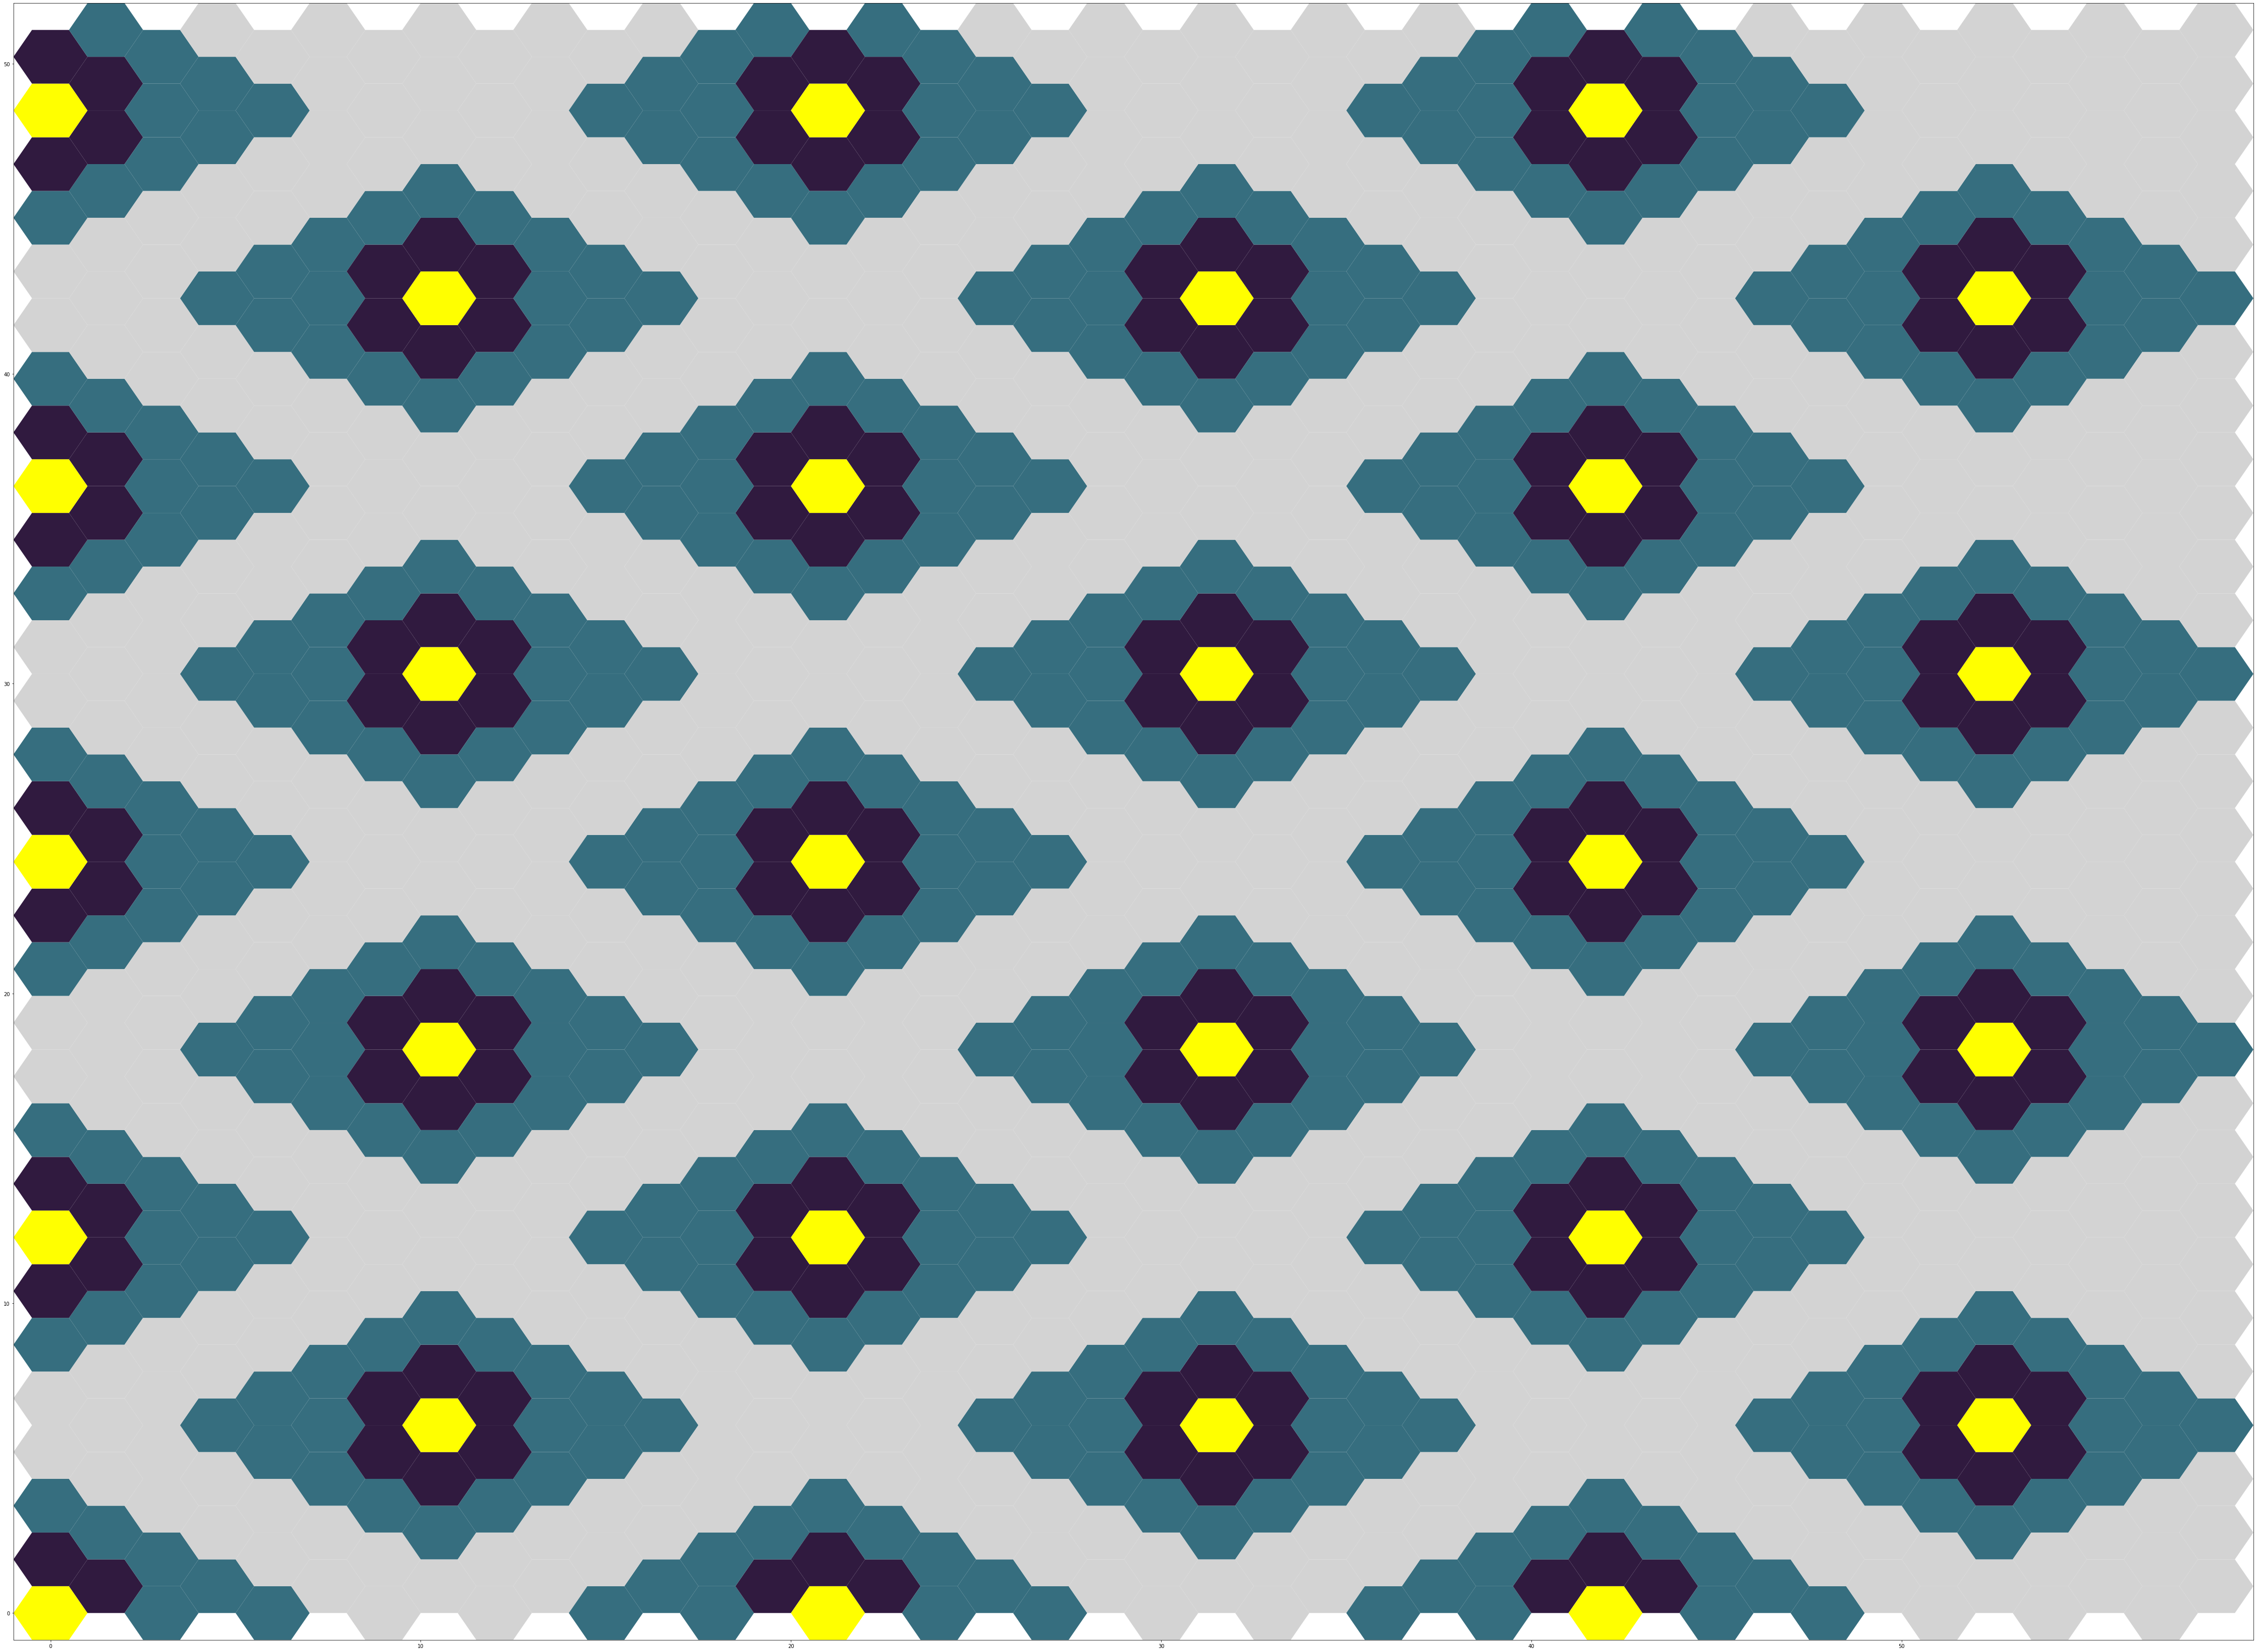

In [70]:
plt.rcParams["figure.figsize"] = (COLS * 2, ROWS * 2)
fig, ax = plt.subplots()
ax.set_xlim([-1, 1.5 * COLS - 0.5])
ax.set_ylim([-sqrt(3) / 2, sqrt(3) * ROWS])

centers = []
for r in range(0, ROWS):
    for c in range(0, COLS):
        if (c % 14 == 0 and r % 7 == 0) or (c % 14 == 7 and r % 7 == 3):
            centers.append((c, r))


def calc_color(r, c):
    closest = min(centers, key=lambda p: (p[0] - c) ** 2 + (p[1] - r) ** 2)

    # Center of diamond
    if closest[0] == c and closest[1] == r:
        return "yellow"

    # Ring around center
    if (
        (abs(closest[0] - c) <= 0 and abs(closest[1] - r) <= 1)
        or (abs(closest[0] - c) <= 1 and abs(closest[1] - r) <= 0)
        or (abs(closest[0] - c) <= 1 and closest[1] - r == (1 if c % 2 == 1 else -1))
    ):
        return "#301A3F"

    # Diamond around center
    dy = abs(closest[1] - r)
    dx = abs(closest[0] - c)
    if (
        (closest[0] == c and abs(closest[1] - r) <= 2)
        or (closest[1] == r and abs(closest[0] - c) <= 4)
        or (
            closest[0] != c
            and (dx != 1 or closest[1] - r != (-2 if c % 2 == 1 else 2))
            and dx + dy < 4
        )
        or (dx == 3 and closest[1] - r == (1 if c % 2 == 1 else -1))
    ):
        return "#366E7F"

    return "lightgray"


for r in range(0, ROWS):
    for c in range(0, COLS):
        x = c * 1.5
        y = r * sqrt(3) + (sqrt(3) / 2 if c % 2 == 1 else 0)
        # ax.text(x, y, str(c) + "," + str(r), fontsize=20)
        ax.add_patch(
            Polygon(
                [
                    (x - 1, y),
                    (x - 0.5, y + sqrt(3) / 2),
                    (x + 0.5, y + sqrt(3) / 2),
                    (x + 1, y),
                    (x + 0.5, y - sqrt(3) / 2),
                    (x - 0.5, y - sqrt(3) / 2),
                ],
                color=calc_color(r, c),
                ec=None,
            )
        )